In [1]:
import os
import pandas as pd
from pygam import LogisticGAM, s, f
import matplotlib.pyplot as plt
import seaborn as sns
import pyranges as pr

os.getcwd()

'/home/bee/code/mutrate'

In [3]:
# Import the scripts
from scr.landscapes import sig_per_region

In [4]:
# Load the input data
selected_sbs = ["SBSblood", "SBS1", "SBS8", "SBS7a", "SBS9", "SBS17b", "SBS18"]

### Filter B memory cells

In [ ]:
vcf_path = "data/landscapes/som2_indel_SNV_allDF_v2.vcf"
metadata_path = "data/landscapes/colonyinfo_AX001_KX001_KX002_KX003_TX001_TX002_CB001.txt"

In [ ]:
vcf_b = sig_per_region.vcf_preselect(vcf_path, metadata_path, ["B Memory"], save_to_csv=False)

### Building Initial Signature Matrix

In [5]:
cosmic_path = "data/landscapes/signatures/COSMIC_v3_SBS_GRCh37.txt"

sbs_blood = pd.read_csv("data/landscapes/signatures/sigfit_cosmic3_bloodsig_Aug2020.txt", 
                        sep="\t", index_col=0)
sbs_blood.rename(columns={"Signature.Blood": "SBSblood"}, inplace=True)

/tmp/ipykernel_1688/1268899446.py:5: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  sbs_blood.rename(columns={"Signature.Blood": "SBSblood"}, inplace=True)


In [ ]:
cosmic_matrix = sig_per_region.sign_matrix_compose(cosmic_path, 
                                                   sbs_blood, 
                                                   selected_sbs, 
                                                   save_to_csv=False)

### Signatures per 1Mb

In [4]:
vcf_b = pd.read_csv("data/landscapes/SNV_BMemoryDF_with_sub_and_coords.vcf", sep=",")

cosmic_path = "data/landscapes/signatures/initial_cosmic_subset.tsv"

try:
    cosmic_matrix = pd.read_csv(cosmic_path, index_col=0, sep="\t")
except FileNotFoundError:
    cosmic_matrix = sig_per_region.sign_matrix_compose(cosmic_path, sbs_blood, selected_sbs, save_to_csv=True)

In [5]:
signatures_per_mb = sig_per_region.signatures_broad_region(vcf_b, 
                                                     cosmic_path=cosmic_path, 
                                                     selected_sbs=selected_sbs, 
                                                     save_to_csv=True)

signatures_per_mb

Converged after 24 iterations.
Progress: 0/2898 regions processed
Converged after 40 iterations.
Progress: 1/2898 regions processed
Converged after 46 iterations.
Progress: 2/2898 regions processed
Converged after 59 iterations.
Progress: 3/2898 regions processed
Converged after 11 iterations.
Progress: 4/2898 regions processed
Converged after 47 iterations.
Progress: 5/2898 regions processed
Converged after 54 iterations.
Progress: 6/2898 regions processed
Progress: 7/2898 regions processed
Converged after 48 iterations.
Progress: 8/2898 regions processed
Progress: 9/2898 regions processed
Progress: 10/2898 regions processed
Converged after 99 iterations.
Progress: 11/2898 regions processed
Progress: 12/2898 regions processed
Converged after 47 iterations.
Progress: 13/2898 regions processed
Progress: 14/2898 regions processed
Converged after 46 iterations.
Progress: 15/2898 regions processed
Progress: 16/2898 regions processed
Converged after 17 iterations.
Progress: 17/2898 regions 

,mb_id,SBSblood,SBS1,SBS8,SBS7a,SBS9,SBS17b,SBS18
0,chr1:19000001,0.598329,0.319873,0.0,0.081798,0.000000,0.0,0.000000
1,chr1:25000001,0.905633,0.038952,0.0,0.055415,0.000000,0.0,0.000000
2,chr1:26000001,0.591434,0.279041,0.0,0.000000,0.000000,0.0,0.129525
3,chr1:27000001,0.433811,0.000000,0.0,0.253307,0.196633,0.0,0.116249
4,chr1:28000001,1.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...,...
2893,chr9:45000001,0.000000,1.000000,0.0,0.000000,0.000000,0.0,0.000000
2894,chr2:243000001,0.000000,0.000000,0.0,0.000000,1.000000,0.0,0.000000
2895,chr10:39000001,0.000000,0.000000,0.0,0.000000,1.000000,0.0,0.000000
2896,chrY:20000001,1.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000


In [13]:
signatures_per_mb.to_csv("data/landscapes/signatures/signatures_per_mb.csv", sep="\t", index=False)

### Signatures per 10kb

In [5]:
# signatures_per_mb = pd.read_csv("data/landscapes/signatures/signatures_per_mb.tsv", sep="\t", index_col=0)
vcf_path = "data/landscapes/SNV_BMemoryDF_with_sub_and_coords.vcf"
cosmic_path = "data/landscapes/signatures/initial_cosmic_subset.tsv"
signatures_per_mb = pd.read_csv("data/landscapes/signatures/signatures_per_mb.csv", sep="\t", index_col=0)

In [6]:
signatures_per_mb = signatures_per_mb[selected_sbs]
signatures_per_mb

,SBSblood,SBS1,SBS8,SBS7a,SBS9,SBS17b,SBS18
mb_id,,,,,,,
chr1:19000001,0.598329,0.319873,0.0,0.081798,0.000000,0.0,0.000000
chr1:25000001,0.905633,0.038952,0.0,0.055415,0.000000,0.0,0.000000
chr1:26000001,0.591434,0.279041,0.0,0.000000,0.000000,0.0,0.129525
chr1:27000001,0.433811,0.000000,0.0,0.253307,0.196633,0.0,0.116249
chr1:28000001,1.000000,0.000000,0.0,0.000000,0.000000,0.0,0.000000
...,...,...,...,...,...,...,...
chr9:45000001,0.000000,1.000000,0.0,0.000000,0.000000,0.0,0.000000
chr2:243000001,0.000000,0.000000,0.0,0.000000,1.000000,0.0,0.000000
chr10:39000001,0.000000,0.000000,0.0,0.000000,1.000000,0.0,0.000000


In [7]:
signatures_per_kb = sig_per_region.signatures_narrow_region(vcf_path=vcf_path, 
                                                            cosmic_path=cosmic_path,
                                                            signatures_per_mb=signatures_per_mb,
                                                            selected_sbs=selected_sbs,
                                                            save_to_csv=False)

In [8]:
signatures_per_kb

,SBSblood,SBS1,SBS8,SBS7a,SBS9,SBS17b,SBS18,n_mutations
kb_id,,,,,,,,
chr10:100030001,0,1,0,0,0,0,0,1
chr10:100050001,1,0,0,0,0,0,0,1
chr10:100070001,0,1,0,0,0,0,0,1
chr10:100090001,1,0,0,0,0,0,0,1
chr10:10030001,0,0,0,0,0,1,0,1
...,...,...,...,...,...,...,...,...
chrY:9760001,1,0,0,0,0,0,0,1
chrY:9770001,0,0,0,0,0,0,0,3
chrY:9820001,0,0,0,0,1,0,0,1


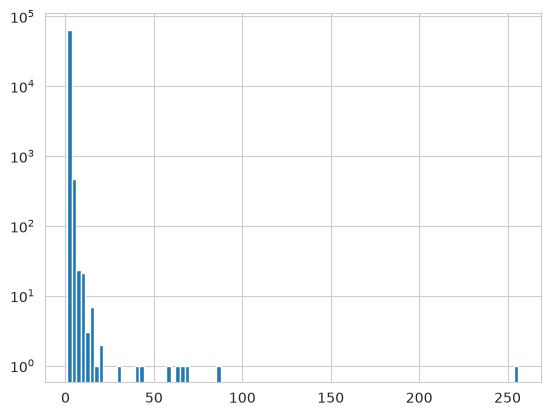

In [11]:
plt.hist(signatures_per_kb["n_mutations"], bins=100)
plt.yscale('log')

### Generalized additive model

In [12]:
chr_coords = pd.read_csv("data/landscapes/hg19_1Mb_coords.csv")
chr_coords

,chr,start,end,kb_id,mb_id
0,chr1,1,10000.0,chr1:1,chr1:1
1,chr1,10001,20000.0,chr1:10001,chr1:1
2,chr1,20001,30000.0,chr1:20001,chr1:1
3,chr1,30001,40000.0,chr1:30001,chr1:1
4,chr1,40001,50000.0,chr1:40001,chr1:1
...,...,...,...,...,...
309574,chrY,59330001,59340000.0,chrY:59330001,chrY:59000001
309575,chrY,59340001,59350000.0,chrY:59340001,chrY:59000001
309576,chrY,59350001,59360000.0,chrY:59350001,chrY:59000001
309577,chrY,59360001,59370000.0,chrY:59360001,chrY:59000001


In [13]:
genomic_features = pd.read_csv("data/landscapes/features/features_10kb.csv")

genomic_features.set_index("kb_id", inplace=True)
genomic_features.drop(columns=["mb_id"], inplace=True)
genomic_features

/tmp/ipykernel_6436/2772234633.py:3: Pandas4Warning: The inplace keyword in DataFrame.set_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features.set_index("kb_id", inplace=True)
/tmp/ipykernel_6436/2772234633.py:4: Pandas4Warning: The inplace keyword in DataFrame.drop is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features.drop(columns=["mb_id"], inplace=True)


,A.C.G.T,cpg_fraction,replication_wave_signal
kb_id,,,
chr1:1,NaN,0.0000,NaN
chr1:10001,0.5923,0.0000,NaN
chr1:20001,0.5174,0.1075,48.091469
chr1:30001,0.4712,0.0000,48.124332
chr1:40001,0.3561,0.0000,48.220527
...,...,...,...
chr22:51260001,NaN,0.0000,46.454624
chr22:51270001,NaN,0.0000,45.836917
chr22:51280001,NaN,0.0000,NaN


#### Merge genomic features in one table

In [14]:
gene_expression = pd.read_csv("data/landscapes/features/expression_quartiles.csv").drop(["chr", "start", "end"], axis=1)
gene_expression

,expression_quartile,kb_id
0,intergenic,chr1:1
1,intergenic,chr1:10001
2,intergenic,chr1:20001
3,Q0,chr1:30001
4,intergenic,chr1:40001
...,...,...
309574,intergenic,chrY:59330001
309575,intergenic,chrY:59340001
309576,intergenic,chrY:59350001
309577,intergenic,chrY:59360001


In [15]:
genomic_features = genomic_features.join(gene_expression.set_index("kb_id"), how="left")

#### Merge genomic features with an effector variable

In [16]:
signatures_per_kb.reset_index(inplace=True)
genomic_features.reset_index(inplace=True)
genomic_features.rename(columns={"index": "kb_id"}, inplace=True)

genomic_features["kb_id"] = genomic_features["kb_id"].astype("string")
signatures_per_kb["kb_id"] = signatures_per_kb["kb_id"].astype("string")

/tmp/ipykernel_6436/4070735541.py:1: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  signatures_per_kb.reset_index(inplace=True)
/tmp/ipykernel_6436/4070735541.py:2: Pandas4Warning: The inplace keyword in DataFrame.reset_index is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features.reset_index(inplace=True)
/tmp/ipykernel_6436/4070735541.py:3: Pandas4Warning: The inplace keyword in DataFrame.rename is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features.rename(columns={"index": "kb_id"}, inplace=True)


In [18]:
genomic_features_with_signatures = genomic_features.merge(
    signatures_per_kb,
    on="kb_id",
    how="inner",
    validate="one_to_one",
).set_index("kb_id")

genomic_feature_columns = genomic_features.columns.drop("kb_id")
genomic_features_vs_sign = genomic_features_with_signatures[
    [*genomic_feature_columns, "SBS9", "SBS1", "SBSblood", "n_mutations"]
]

In [19]:
genomic_features_vs_sign

,A.C.G.T,cpg_fraction,replication_wave_signal,expression_quartile,SBS9,SBS1,SBSblood,n_mutations
kb_id,,,,,,,,
chr1:830001,0.5093,0.0306,67.385025,intergenic,0,0,1,1
chr1:850001,0.6279,0.1238,70.357795,intergenic,0,0,1,1
chr1:870001,0.6734,0.4505,73.392487,Q0,0,0,0,1
chr1:940001,0.5431,0.0746,81.225182,Q4,0,0,0,1
chr1:1110001,0.6356,0.0577,80.045149,Q0,0,0,1,1
...,...,...,...,...,...,...,...,...
chr22:50910001,0.5991,0.1854,80.964899,Q3,0,0,1,1
chr22:51010001,0.5779,0.0767,80.608262,Q4,0,1,0,1
chr22:51080001,0.4468,0.0000,81.122783,intergenic,0,0,0,1


#### Filtering of the genomic regions

In [20]:
mask = ~genomic_features_vs_sign.index.str.split(":").str[0].isin({"chrX", "chrY"})
genomic_features_vs_sign = genomic_features_vs_sign[mask]

In [21]:
genomic_features_vs_sign.dropna(inplace=True)

/tmp/ipykernel_6436/465516023.py:1: Pandas4Warning: The inplace keyword in DataFrame.dropna is deprecated and will be removed in a future version (PDEP-8).
See https://pandas.pydata.org/docs/dev/whatsnew/v3.1.0.html#deprecation-inplace for more details.
  genomic_features_vs_sign.dropna(inplace=True)


hg19 genome
+ IgH locus coordinates – chr14:106,052,774-107,288,051 orientation -
+ IgL locus coordinates – chr22:22,380,474-23,265,085 orientation +
+ IgK locus coordinates – chr2:89,156,874-90,274,235 orientation +


In [22]:
region_ids = genomic_features_vs_sign.index.to_series().astype("string")
mask_igh = (
    region_ids.str.split(":").str[0] == "chr14"
) & region_ids.str.split(":").str[1].astype(int).between(
    106052774, 107288051
)
mask_igl = (
    region_ids.str.split(":").str[0] == "chr22"
) & region_ids.str.split(":").str[1].astype(int).between(
    22380474, 23265085
)
mask_igk = (
    region_ids.str.split(":").str[0] == "chr2"
) & region_ids.str.split(":").str[1].astype(int).between(
    89156874, 90274235
)

In [23]:
genomic_features_vs_sign = genomic_features_vs_sign.loc[~(mask_igh | mask_igl | mask_igk)]

In [24]:
genomic_features_vs_sign

,A.C.G.T,cpg_fraction,replication_wave_signal,expression_quartile,SBS9,SBS1,SBSblood,n_mutations
kb_id,,,,,,,,
chr1:830001,0.5093,0.0306,67.385025,intergenic,0,0,1,1
chr1:850001,0.6279,0.1238,70.357795,intergenic,0,0,1,1
chr1:870001,0.6734,0.4505,73.392487,Q0,0,0,0,1
chr1:940001,0.5431,0.0746,81.225182,Q4,0,0,0,1
chr1:1110001,0.6356,0.0577,80.045149,Q0,0,0,1,1
...,...,...,...,...,...,...,...,...
chr22:50910001,0.5991,0.1854,80.964899,Q3,0,0,1,1
chr22:51010001,0.5779,0.0767,80.608262,Q4,0,1,0,1
chr22:51080001,0.4468,0.0000,81.122783,intergenic,0,0,0,1


#### Training of the model

In [25]:
model_data = genomic_features_vs_sign.dropna().copy()
model_data["expression_quartile"] = pd.Categorical(
    model_data["expression_quartile"], categories=["Q0", "Q1", "Q2", "Q3", "Q4", "intergenic"]
    ).codes
X, y = model_data.iloc[:, :-4].to_numpy(dtype=float), model_data.iloc[:, -1].to_numpy(dtype=float)

In [26]:
y[0:20]

array([1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1., 1.,
       2., 1., 1.])

In [46]:
full_gam = LogisticGAM(s(0, n_splines=10) + s(1, n_splines=10) + s(2, n_splines=10) + f(3)).fit(X, y)
full_gam.summary()

LogisticGAM                                                                                               
=============================================== ==========================================================
Distribution:                      BinomialDist Effective DoF:                                     23.6295
Link Function:                        LogitLink Log Likelihood:                                -35707.0015
Number of Samples:                        62122 AIC:                                             71461.262
                                                AICc:                                           71461.2823
                                                UBRE:                                               3.1506
                                                Scale:                                                 1.0
                                                Pseudo R-Squared:                                   0.1342
Feature Function                  Lam

/tmp/ipykernel_1688/3721115940.py:2: UserWarning: KNOWN BUG: p-values computed in this summary are likely much smaller than they should be. 
 
Please do not make inferences based on these values! 

Collaborate on a solution, and stay up to date at: 
github.com/dswah/pyGAM/issues/163 

  full_gam.summary()


In [47]:
full_gam.statistics_["pseudo_r2"]["explained_deviance"] * 100

np.float64(13.422901967028922)

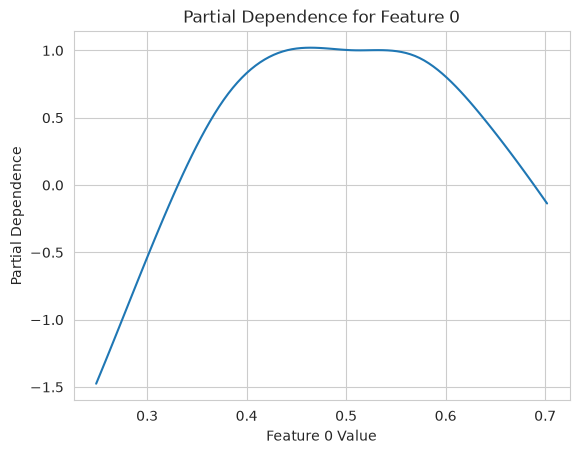

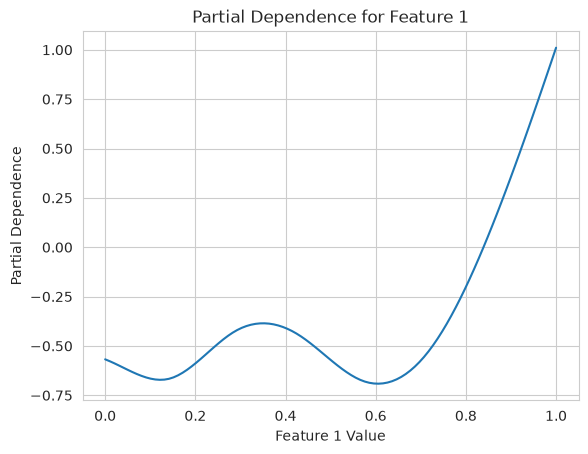

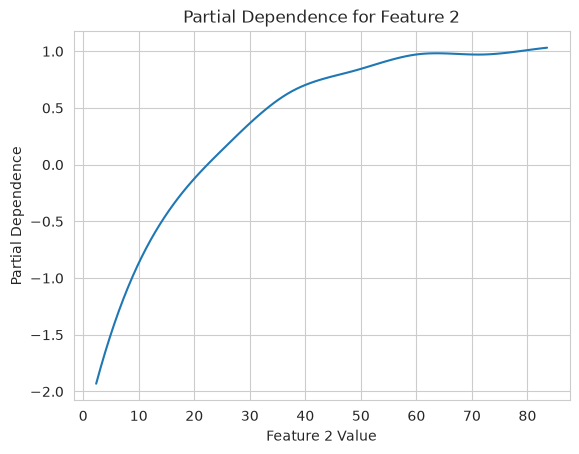

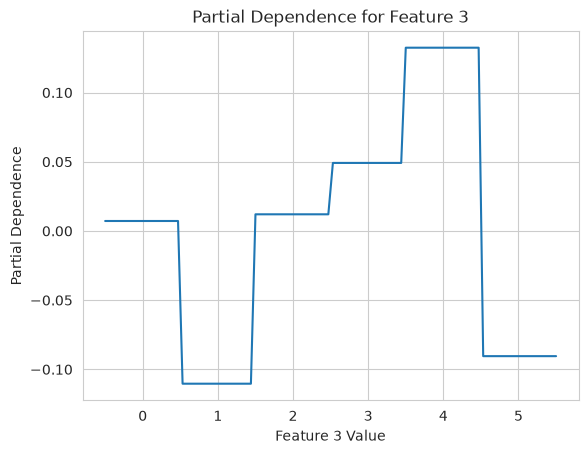

In [48]:
for i in range(X.shape[1]):
    XX = full_gam.generate_X_grid(term=i)
    plt.figure()
    plt.title(f"Partial Dependence for Feature {i}")
    plt.plot(XX[:, i], full_gam.partial_dependence(term=i, X=XX))
    plt.xlabel(f"Feature {i} Value")
    plt.ylabel("Partial Dependence")
    plt.show()

In [49]:
full_deviance = full_gam.statistics_["pseudo_r2"]["explained_deviance"]

In [51]:
full_deviance

np.float64(0.13422901967028922)

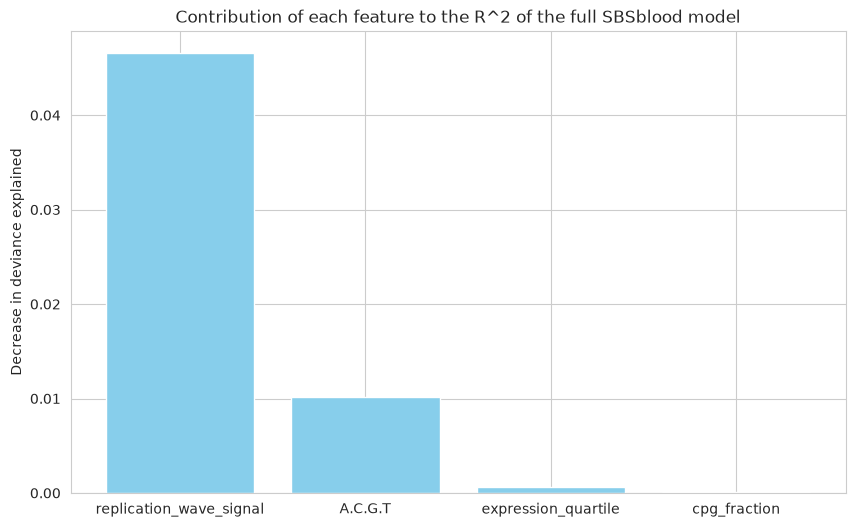

In [50]:
feature_names = genomic_features_vs_sign.columns[:-3].to_list()
feature_contributions = []

for feature in range(X.shape[1]):
    remaining = [i for i in range(X.shape[1]) if i != feature]
    X_reduced = X[:, remaining]
    terms = s(0, n_splines=10)

    for j in range(1, len(remaining)):
        terms += s(j, n_splines=10)

    reduced_gam = LogisticGAM(terms).fit(X_reduced, y)
    reduced_deviance = reduced_gam.statistics_["pseudo_r2"]["explained_deviance"]

    contribution = full_deviance - reduced_deviance
    feature_contributions.append(contribution)

feature_names, feature_contributions = zip(
    *sorted(zip(feature_names, feature_contributions), 
            key=lambda pair: pair[1], 
            reverse=True))

fig, ax = plt.subplots(figsize=(10, 6))

ax.bar(feature_names, feature_contributions, color='skyblue')
plt.ylabel("Decrease in deviance explained")
plt.title("Contribution of each feature to the R^2 of the full SBSblood model")
plt.show()

### Visualize expression agains different signatures

In [41]:
sign_vs_expression = genomic_features_vs_sign.groupby("expression_quartile").mean()

In [42]:
sign_vs_expression = sign_vs_expression.drop(columns=["n_mutations", "A.C.G.T", "cpg_fraction", "replication_wave_signal"])

In [39]:
sign_vs_expression

,SBS9,SBS1,SBSblood
expression_quartile,,,
Q0,969,282,1317
Q1,1214,295,1422
Q2,2360,711,3667
Q3,979,501,2905
Q4,662,342,2274
intergenic,14658,2240,12001


<Axes: xlabel='expression_quartile', ylabel='proportion'>

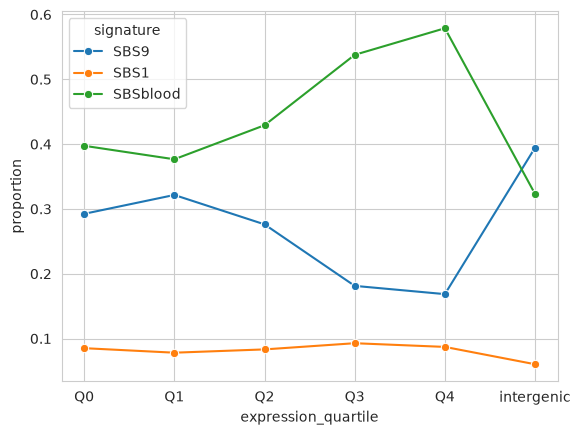

In [43]:
plot_data = sign_vs_expression.reset_index().melt(
    id_vars="expression_quartile",
    var_name="signature",
    value_name="proportion",
)
sns.lineplot(
    data=plot_data,
    x="expression_quartile",
    y="proportion",
    hue="signature",
    marker="o",
)